Q1 annual_income 0.608
Q1 number_of_courses_viewed 0.723
Q1 interaction_count 0.765
Q1 lead_score 0.788
Q2 0.732


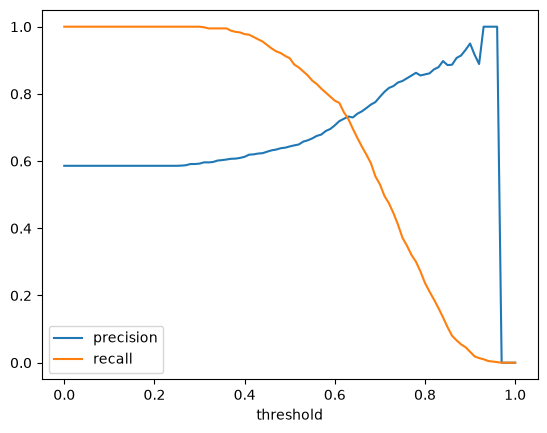

Q3 0.63
Q4 0.41
Q5 0.007
Q6 1e-06 0.617 0.019
Q6 0.001 0.749 0.01
Q6 1 0.732 0.007


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)

cat = ['lead_source', 'industry', 'employment_status', 'location']
num = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
df[cat] = df[cat].fillna('NA')
df[num] = df[num].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
y_train = df_train.converted.values
y_val = df_val.converted.values
df_train = df_train.drop(columns='converted').reset_index(drop=True)
df_val = df_val.drop(columns='converted').reset_index(drop=True)

# Q1
for c in num:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print("Q1", c, round(auc, 3))

# Q2
feats = cat + num
dv = DictVectorizer(sparse=False)
Xt = dv.fit_transform(df_train[feats].to_dict(orient='records'))
Xv = dv.transform(df_val[feats].to_dict(orient='records'))
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000).fit(Xt, y_train)
y_pred = model.predict_proba(Xv)[:, 1]
print("Q2", round(roc_auc_score(y_val, y_pred), 3))

# Q3 e Q4
rows = []
for t in np.arange(0.0, 1.01, 0.01):
    pred = y_pred >= t
    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    fn = ((pred == 0) & (y_val == 1)).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    rows.append((round(t, 2), p, r, f1))
sc = pd.DataFrame(rows, columns=['t', 'p', 'r', 'f1'])

plt.plot(sc.t, sc.p, label='precision')
plt.plot(sc.t, sc.r, label='recall')
plt.legend(); plt.xlabel('threshold'); plt.show()

nz = sc[~((sc.p == 0) & (sc.r == 0))].copy()
nz['diff'] = (nz.p - nz.r).abs()
print("Q3", nz.sort_values('diff').iloc[0].t)
print("Q4", sc.sort_values('f1', ascending=False).iloc[0].t)

# Q5 e Q6
def cv(C):
    kf = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for tr, va in kf.split(df_full_train):
        d_tr = df_full_train.iloc[tr]; d_va = df_full_train.iloc[va]
        y_tr = d_tr.converted.values; y_va = d_va.converted.values
        dv2 = DictVectorizer(sparse=False)
        X1 = dv2.fit_transform(d_tr[feats].to_dict(orient='records'))
        X2 = dv2.transform(d_va[feats].to_dict(orient='records'))
        m = LogisticRegression(solver='liblinear', C=C, max_iter=1000).fit(X1, y_tr)
        scores.append(roc_auc_score(y_va, m.predict_proba(X2)[:, 1]))
    return np.mean(scores), np.std(scores)

print("Q5", round(cv(1.0)[1], 3))
for C in [0.000001, 0.001, 1]:
    m, s = cv(C)
    print("Q6", C, round(m, 3), round(s, 3))